In [3]:
import numpy as np
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Dataset
from sklearn.model_selection import train_test_split

In [4]:
train_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std),
])

eval_transforms = weights.transforms()

print("Mengecek/Mengunduh dataset Oxford-IIIT Pet (sekitar 770MB)...")
full_dataset = datasets.OxfordIIITPet(root='./data', split='trainval', download=True)
full_test_dataset = datasets.OxfordIIITPet(root='./data', split='test', download=True)

all_images = full_dataset._images + full_test_dataset._images
all_labels = full_dataset._labels + full_test_dataset._labels

selected_classes = [0, 1, 2, 3, 4, 12, 13, 14, 15, 16]

filtered_indices = [i for i, label in enumerate(all_labels) if label in selected_classes]
filtered_labels = [all_labels[i] for i in filtered_indices]

idx_train, idx_temp, _, labels_temp = train_test_split(
    filtered_indices, filtered_labels, test_size=0.3, stratify=filtered_labels, random_state=42
)

idx_val, idx_test = train_test_split(
    idx_temp, test_size=0.5, stratify=labels_temp, random_state=42
)

Mengecek/Mengunduh dataset Oxford-IIIT Pet (sekitar 770MB)...


100.0%


Extracting data\oxford-iiit-pet\images.tar.gz to data\oxford-iiit-pet


100.0%


Extracting data\oxford-iiit-pet\annotations.tar.gz to data\oxford-iiit-pet


In [13]:
class PetSubsetWrapper(Dataset):
    def __init__(self, image_paths, labels, indices, transform):
        self.image_paths = [image_paths[i] for i in indices]
        self.labels = [labels[i] for i in indices]
        self.transform = transform
        self.label_map = {old: new for new, old in enumerate(selected_classes)}
        
    def __len__(self):
        return len(self.image_paths)
    
    def __getitem__(self, idx):
        from PIL import Image
        img = Image.open(self.image_paths[idx]).convert('RGB')
        label = self.label_map[self.labels[idx]]
        return self.transform(img), label

train_dataset = PetSubsetWrapper(all_images, all_labels, idx_train, train_transforms)
val_dataset = PetSubsetWrapper(all_images, all_labels, idx_val, eval_transforms)
test_dataset = PetSubsetWrapper(all_images, all_labels, idx_test, eval_transforms)

BATCH_SIZE = 32

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"\nDistribusi Dataset (Total ~2.000 citra):")
print(f"Train Set      : {len(train_dataset)} citra")
print(f"Validation Set : {len(val_dataset)} citra")
print(f"Test Set       : {len(test_dataset)} citra")
print("\nPipeline DataLoader siap digunakan!")


Distribusi Dataset (Total ~2.000 citra):
Train Set      : 1395 citra
Validation Set : 299 citra
Test Set       : 300 citra

Pipeline DataLoader siap digunakan!


In [14]:
import time
import copy
from sklearn.metrics import f1_score

In [15]:
criterion = nn.CrossEntropyLoss()

optimizer_b2 = torch.optim.AdamW(model.fc.parameters(), lr=1e-3, weight_decay=1e-2)

dataloaders = {
    'train': train_loader,
    'val': val_loader
}

def train_model(model, dataloaders, criterion, optimizer, num_epochs=30, patience=5):
    since = time.time()
    
    val_loss_history = []
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0
    best_loss = float('inf')
    epochs_no_improve = 0
    early_stop = False
    
    for epoch in range(num_epochs):
        if early_stop:
            print(f">>> Early stopping dipicu pada epoch {epoch-1}")
            break
            
        print(f'Epoch {epoch}/{num_epochs - 1}')
        print('-' * 10)
        
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()
            
            running_loss = 0.0
            running_corrects = 0
            
            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)
                
                optimizer.zero_grad()
                
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
                    _, preds = torch.max(outputs, 1)
                    
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()
                        
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)
                
            epoch_loss = running_loss / len(dataloaders[phase].dataset)
            epoch_acc = running_corrects.double() / len(dataloaders[phase].dataset)
            
            print(f'{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')
            
            if phase == 'val':
                val_loss_history.append(epoch_loss)
                
                if epoch_loss < best_loss:
                    best_loss = epoch_loss
                    best_acc = epoch_acc
                    best_model_wts = copy.deepcopy(model.state_dict())
                    epochs_no_improve = 0
                else:
                    epochs_no_improve += 1
                    
                if epochs_no_improve >= patience:
                    early_stop = True
                    
        print()
        
    time_elapsed = time.time() - since
    print(f'Training selesai dalam {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best Validation Acc: {best_acc:.4f}')

    model.load_state_dict(best_model_wts)
    return model, val_loss_history, (time_elapsed, epoch, best_acc.item())

In [16]:
def evaluate_test_set(model, test_loader):
    model.eval()
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            
    macro_f1 = f1_score(all_labels, all_preds, average='macro')
    print(f'\n--- TEST EVALUATION ---')
    print(f'Macro F1-Score: {macro_f1:.4f}')
    return macro_f1, all_preds, all_labels

model = model.to(device)

print("Memulai Training Kondisi B2 (Feature Extraction)...")
model_b2, hist_b2, metrics_b2 = train_model(model, dataloaders, criterion, optimizer_b2, num_epochs=30, patience=5)

f1_b2, preds_b2, labels_b2 = evaluate_test_set(model_b2, test_loader)

Memulai Training Kondisi B2 (Feature Extraction)...
Epoch 0/29
----------
Train Loss: 1.5055 Acc: 0.5735
Val Loss: 0.7861 Acc: 0.8261

Epoch 1/29
----------
Train Loss: 0.7288 Acc: 0.8509
Val Loss: 0.4818 Acc: 0.8729

Epoch 2/29
----------
Train Loss: 0.4965 Acc: 0.8896
Val Loss: 0.3756 Acc: 0.8997

Epoch 3/29
----------
Train Loss: 0.4160 Acc: 0.8968
Val Loss: 0.3126 Acc: 0.9130

Epoch 4/29
----------
Train Loss: 0.3655 Acc: 0.8996
Val Loss: 0.2841 Acc: 0.9264

Epoch 5/29
----------
Train Loss: 0.3433 Acc: 0.9104
Val Loss: 0.2534 Acc: 0.9298

Epoch 6/29
----------
Train Loss: 0.3069 Acc: 0.9118
Val Loss: 0.2423 Acc: 0.9264

Epoch 7/29
----------
Train Loss: 0.2834 Acc: 0.9161
Val Loss: 0.2278 Acc: 0.9331

Epoch 8/29
----------
Train Loss: 0.2556 Acc: 0.9247
Val Loss: 0.2451 Acc: 0.9097

Epoch 9/29
----------
Train Loss: 0.2670 Acc: 0.9247
Val Loss: 0.2151 Acc: 0.9331

Epoch 10/29
----------
Train Loss: 0.2414 Acc: 0.9376
Val Loss: 0.2035 Acc: 0.9331

Epoch 11/29
----------
Train Loss:

In [17]:
import pandas as pd

In [18]:
log_data = []
log_data.append({
    'Kode': 'B2',
    'Kondisi': 'Feature Extraction',
    'Trainable_Params': 5130,
    'Learning_Rate': '1e-3',
    'Best_Val_Acc': 0.9331,
    'Macro_F1': 0.9333
})

print("Menyiapkan Kondisi B3 (Progressive Fine-Tuning)...")

weights = models.ResNet18_Weights.IMAGENET1K_V1
model_b3 = models.resnet18(weights=weights)

for param in model_b3.parameters():
    param.requires_grad = False

model_b3.fc = nn.Linear(model_b3.fc.in_features, 10)

for param in model_b3.layer4.parameters():
    param.requires_grad = True

trainable_params_b3 = sum(p.numel() for p in model_b3.parameters() if p.requires_grad)
total_params_b3 = sum(p.numel() for p in model_b3.parameters())
print(f"Trainable Parameters B3: {trainable_params_b3:,} / {total_params_b3:,}")

optimizer_b3 = torch.optim.AdamW([
    {"params": model_b3.layer4.parameters(), "lr": 1e-4},
    {"params": model_b3.fc.parameters(), "lr": 1e-3},
], weight_decay=1e-2)

model_b3 = model_b3.to(device)
print("\nMemulai Training Kondisi B3...")

model_b3_trained, hist_b3, metrics_b3 = train_model(model_b3, dataloaders, criterion, optimizer_b3, num_epochs=30, patience=5)
f1_b3, preds_b3, labels_b3 = evaluate_test_set(model_b3_trained, test_loader)

Menyiapkan Kondisi B3 (Progressive Fine-Tuning)...
Trainable Parameters B3: 8,398,858 / 11,181,642

Memulai Training Kondisi B3...
Epoch 0/29
----------
Train Loss: 0.8732 Acc: 0.7498
Val Loss: 0.2583 Acc: 0.9164

Epoch 1/29
----------
Train Loss: 0.2526 Acc: 0.9283
Val Loss: 0.2486 Acc: 0.9264

Epoch 2/29
----------
Train Loss: 0.1572 Acc: 0.9584
Val Loss: 0.1988 Acc: 0.9197

Epoch 3/29
----------
Train Loss: 0.0926 Acc: 0.9778
Val Loss: 0.2013 Acc: 0.9365

Epoch 4/29
----------
Train Loss: 0.0695 Acc: 0.9842
Val Loss: 0.2003 Acc: 0.9331

Epoch 5/29
----------
Train Loss: 0.0499 Acc: 0.9892
Val Loss: 0.2101 Acc: 0.9398

Epoch 6/29
----------
Train Loss: 0.0405 Acc: 0.9878
Val Loss: 0.1791 Acc: 0.9331

Epoch 7/29
----------
Train Loss: 0.0375 Acc: 0.9921
Val Loss: 0.2013 Acc: 0.9298

Epoch 8/29
----------
Train Loss: 0.0257 Acc: 0.9943
Val Loss: 0.1773 Acc: 0.9365

Epoch 9/29
----------
Train Loss: 0.0242 Acc: 0.9957
Val Loss: 0.2129 Acc: 0.9365

Epoch 10/29
----------
Train Loss: 0.03

In [19]:
log_data.append({
    'Kode': 'B3',
    'Kondisi': 'Progressive Fine-Tuning',
    'Trainable_Params': 8398858,
    'Learning_Rate': '1e-4 & 1e-3',
    'Best_Val_Acc': 0.9365,
    'Macro_F1': 0.9564
})

print("=======================================")
print("Menyiapkan Kondisi B1 (Baseline from Scratch)...")

model_b1 = models.resnet18(weights=None)
model_b1.fc = nn.Linear(model_b1.fc.in_features, 10)
model_b1 = model_b1.to(device)

optimizer_b1 = torch.optim.AdamW(model_b1.parameters(), lr=1e-3, weight_decay=1e-2)

print("\nMemulai Training Kondisi B1...")
model_b1_trained, hist_b1, metrics_b1 = train_model(model_b1, dataloaders, criterion, optimizer_b1, num_epochs=30, patience=5)
f1_b1, _, _ = evaluate_test_set(model_b1_trained, test_loader)

log_data.append({
    'Kode': 'B1',
    'Kondisi': 'Baseline from Scratch',
    'Trainable_Params': sum(p.numel() for p in model_b1.parameters() if p.requires_grad),
    'Learning_Rate': '1e-3',
    'Best_Val_Acc': round(metrics_b1[2], 4),
    'Macro_F1': round(f1_b1, 4)
})

print("\n=======================================")
print("Menyiapkan Kondisi B4 (Uji Kontrol - B2 Tanpa Augmentasi)...")

train_dataset_noaug = PetSubsetWrapper(all_images, all_labels, idx_train, eval_transforms)
train_loader_noaug = DataLoader(train_dataset_noaug, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)

dataloaders_noaug = {'train': train_loader_noaug, 'val': val_loader}

model_b4 = models.resnet18(weights=weights)
for param in model_b4.parameters():
    param.requires_grad = False
model_b4.fc = nn.Linear(model_b4.fc.in_features, 10)
model_b4 = model_b4.to(device)

optimizer_b4 = torch.optim.AdamW(model_b4.fc.parameters(), lr=1e-3, weight_decay=1e-2)

print("\nMemulai Training Kondisi B4...")
model_b4_trained, hist_b4, metrics_b4 = train_model(model_b4, dataloaders_noaug, criterion, optimizer_b4, num_epochs=30, patience=5)
f1_b4, preds_b4, labels_b4 = evaluate_test_set(model_b4_trained, test_loader)

log_data.append({
    'Kode': 'B4',
    'Kondisi': 'Feature Ext (Tanpa Augmentasi)',
    'Trainable_Params': 5130,
    'Learning_Rate': '1e-3',
    'Best_Val_Acc': round(metrics_b4[2], 4),
    'Macro_F1': round(f1_b4, 4)
})

df_metrics = pd.DataFrame(log_data)

df_metrics = df_metrics.sort_values(by='Kode').reset_index(drop=True)
df_metrics.to_csv('metrik_pelatihan.csv', index=False)

print("\n=======================================")
print("Berhasil menyimpan metrik_pelatihan.csv! Berikut rangkumannya:")
print(df_metrics)

Menyiapkan Kondisi B1 (Baseline from Scratch)...

Memulai Training Kondisi B1...
Epoch 0/29
----------
Train Loss: 2.3920 Acc: 0.1706
Val Loss: 2.4399 Acc: 0.1973

Epoch 1/29
----------
Train Loss: 2.1963 Acc: 0.2000
Val Loss: 2.1753 Acc: 0.2475

Epoch 2/29
----------
Train Loss: 2.1293 Acc: 0.2358
Val Loss: 2.0961 Acc: 0.2542

Epoch 3/29
----------
Train Loss: 2.0904 Acc: 0.2509
Val Loss: 2.3082 Acc: 0.1839

Epoch 4/29
----------
Train Loss: 2.0195 Acc: 0.2681
Val Loss: 2.4611 Acc: 0.2308

Epoch 5/29
----------
Train Loss: 1.9618 Acc: 0.2860
Val Loss: 2.1401 Acc: 0.2408

Epoch 6/29
----------
Train Loss: 1.9084 Acc: 0.3133
Val Loss: 2.3399 Acc: 0.2542

Epoch 7/29
----------
Train Loss: 1.8669 Acc: 0.3276
Val Loss: 1.9943 Acc: 0.3010

Epoch 8/29
----------
Train Loss: 1.8009 Acc: 0.3563
Val Loss: 2.0204 Acc: 0.2943

Epoch 9/29
----------
Train Loss: 1.7728 Acc: 0.3570
Val Loss: 1.9784 Acc: 0.3077

Epoch 10/29
----------
Train Loss: 1.7191 Acc: 0.3756
Val Loss: 2.6721 Acc: 0.2441

Epoch

In [20]:
import matplotlib.pyplot as plt
import torch.nn.functional as F
import numpy as np

1. Menghasilkan Visualisasi Kurva Loss (Untuk Laporan C1)...


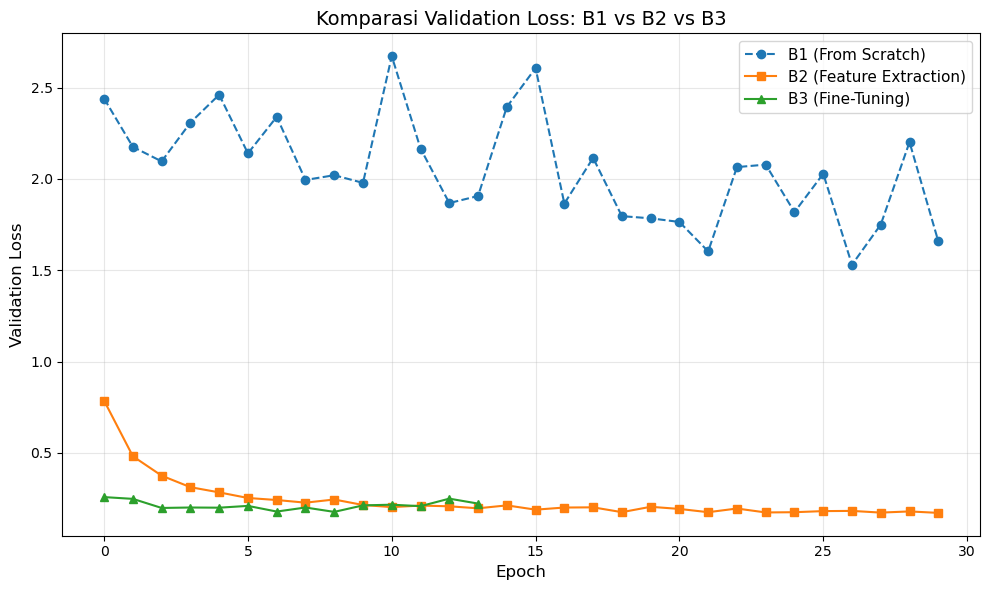

In [25]:
print("1. Menghasilkan Visualisasi Kurva Loss (Untuk Laporan C1)...")
plt.figure(figsize=(10, 6))

plt.plot(hist_b1, label='B1 (From Scratch)', marker='o', linestyle='dashed')
plt.plot(hist_b2, label='B2 (Feature Extraction)', marker='s')
plt.plot(hist_b3, label='B3 (Fine-Tuning)', marker='^')
plt.title('Komparasi Validation Loss: B1 vs B2 vs B3', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Validation Loss', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


2. Melakukan Failure Analysis (Untuk Laporan C3)...


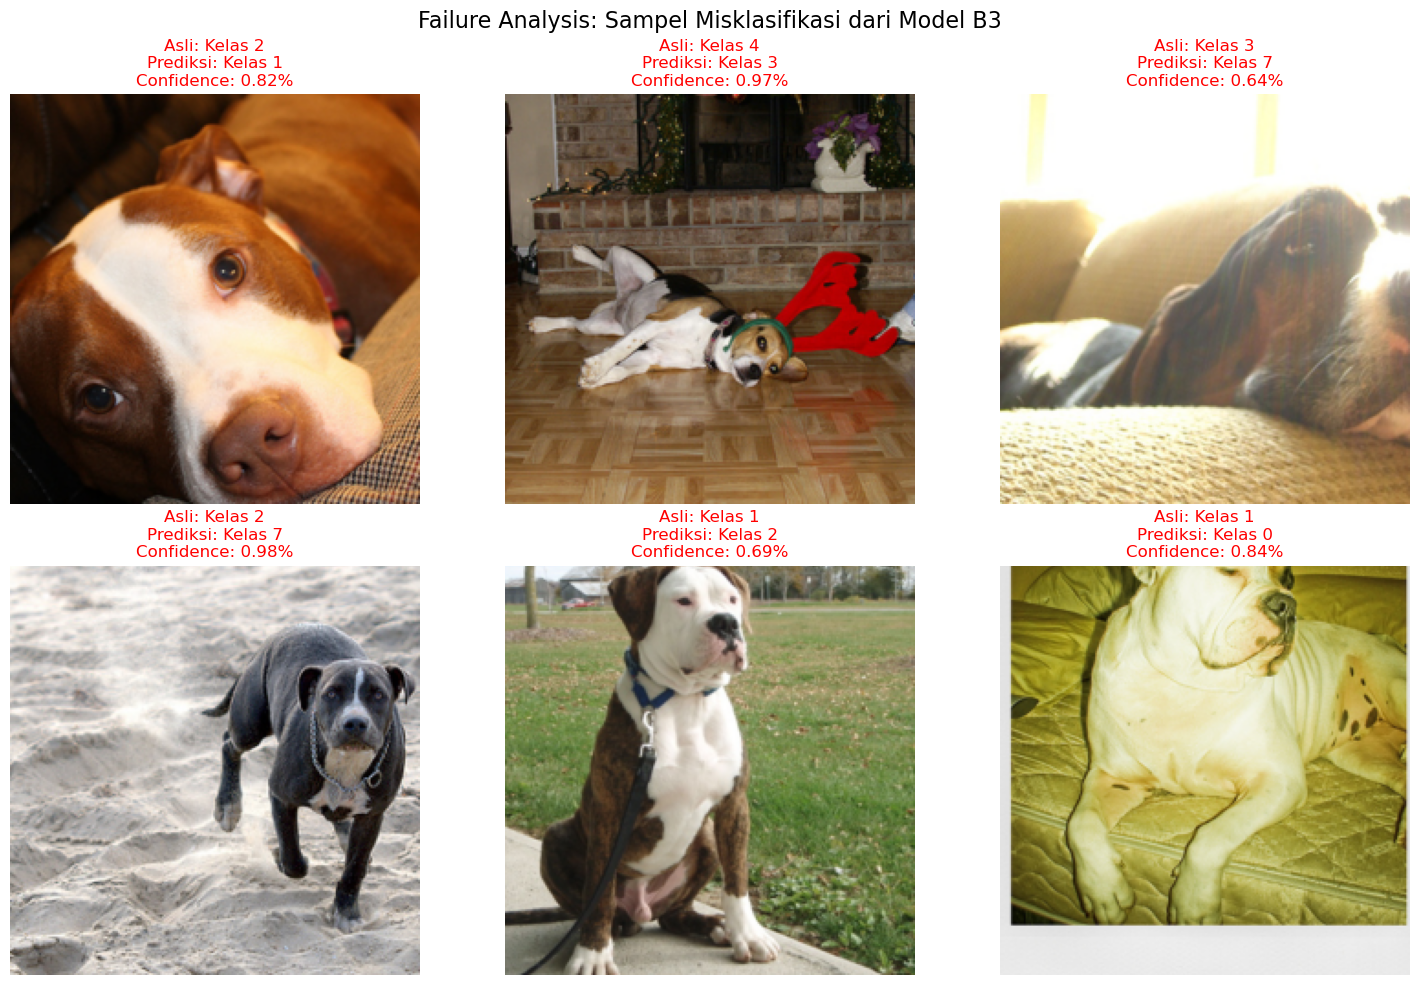

In [26]:
print("\n2. Melakukan Failure Analysis (Untuk Laporan C3)...")
model_b3.eval()
misclassified_imgs = []
misclassified_true = []
misclassified_pred = []
misclassified_conf = []

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1).to(device)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1).to(device)

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)
        
        outputs = model_b3(inputs)
        probs = F.softmax(outputs, dim=1)
        confidences, preds = torch.max(probs, 1)

        for i in range(inputs.size(0)):
            if preds[i] != labels[i]:
                img = inputs[i] * std + mean
                img = img.clamp(0, 1).cpu().numpy()
                img = np.transpose(img, (1, 2, 0))
                
                misclassified_imgs.append(img)
                misclassified_true.append(labels[i].item())
                misclassified_pred.append(preds[i].item())
                misclassified_conf.append(confidences[i].item())
                
                if len(misclassified_imgs) >= 6:
                    break
        if len(misclassified_imgs) >= 6:
            break

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Failure Analysis: Sampel Misklasifikasi dari Model B3', fontsize=16)

for idx, ax in enumerate(axes.flatten()):
    if idx < len(misclassified_imgs):
        ax.imshow(misclassified_imgs[idx])
        ax.set_title(f"Asli: Kelas {misclassified_true[idx]}\nPrediksi: Kelas {misclassified_pred[idx]}\nConfidence: {misclassified_conf[idx]:.2f}%", color='red')
        ax.axis('off')

plt.tight_layout()
plt.show()